# 뇌출혈·뇌동맥류 완료 nnU-Net 전체 Threshold Sweep

Validation 데이터에서 foreground probability threshold를 `0.05`부터 `0.95`까지 `0.05` 간격으로 평가합니다.

- 대상: 완료 checkpoint가 있는 뇌출혈·뇌동맥류 nnU-Net 전체
- 지표: 양성 환자 macro Dice/Recall/Precision, voxel micro Dice/Recall/Precision
- 병변 지표: 탐지율, 미탐 포함/탐지 병변 전용 Dice
- 정상 환자 지표: 오탐 발생률, 환자당 오탐 component 수
- 확률 파일은 케이스별 임시 생성 후 삭제하므로 대용량 확률 볼륨을 누적 저장하지 않습니다.
- 모델별 CSV가 완성되는 즉시 저장하며, 다시 실행하면 완료된 모델은 자동으로 건너뜁니다.

Threshold는 validation에서 선택하고 test에는 선택된 값을 한 번만 적용해야 합니다.

## 1. 경로와 실행 옵션

In [25]:
from pathlib import Path
import json
import subprocess
import time

import pandas as pd

ROOT = Path("/home/stu03/workspace/model")
PYTHON = ROOT / ".venv/bin/python"
SCRIPT = ROOT / "scripts/analysis/threshold_sweep_completed_nnunet.py"
FAST_MODE = True
OUTPUT_ROOT = ROOT / (
    "runs/threshold_sweeps/all_completed_models_fast_no_mirroring"
    if FAST_MODE else "runs/threshold_sweeps/all_completed_models"
)
LOG_FILE = OUTPUT_ROOT / "threshold_sweep.log"
PID_FILE = OUTPUT_ROOT / "threshold_sweep.pid"

# []이면 완료된 모델 전체를 실행합니다.
# 일부만 실행하려면 예: ["A-B00", "A-B01", "H-N00"]
ONLY_EXPERIMENTS = []

# FAST_MODE=True는 미러링 TTA를 끈 빠른 1차 탐색입니다.
# 최종 후보만 FAST_MODE=False로 다시 확인하세요.

# GPU OOM을 줄이기 위해 기본값은 False입니다.
# True는 더 빠를 수 있지만 전체 볼륨 누적 때문에 GPU 메모리를 더 사용합니다.
EVERYTHING_ON_DEVICE = False

# False이면 다른 CUDA 작업(예: 학습)이 있을 때 sweep 시작을 막습니다.
ALLOW_SHARED_GPU = False

for name, path in {"python": PYTHON, "script": SCRIPT}.items():
    print(f"{name:12s}: {path.exists()}  {path}")
print("결과 폴더:", OUTPUT_ROOT)

python      : True  /home/stu03/workspace/model/.venv/bin/python
script      : True  /home/stu03/workspace/model/scripts/analysis/threshold_sweep_completed_nnunet.py
결과 폴더: /home/stu03/workspace/model/runs/threshold_sweeps/all_completed_models_fast_no_mirroring


## 2. 완료 모델 자동 탐색

`checkpoint_final.pth` 또는 `final_selection.json`이 있는 모델만 표시합니다.

In [26]:
list_command = [str(PYTHON), str(SCRIPT), "--repo", str(ROOT), "--list"]
if ONLY_EXPERIMENTS:
    list_command += ["--only", *ONLY_EXPERIMENTS]
subprocess.run(list_command, check=False)

experiment    disease                     dataset  fold                                                                                                                                                                                 model_folder                        checkpoint                                                                            config                                                       data_root                                            results_root
     A-B00   aneurysm Dataset503_TopAneuMRABinary     0                           /home/stu03/workspace/model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansBaselineV1__3d_fullres    checkpoint_best_full_macro.pth        /home/stu03/workspace/model/configs/experiments/aneurysm_binary/A-B00.yaml   /home/stu03/workspace/datasets/aneurysm/v2/model_ready/nnunet /home/stu03/workspace/model/runs/aneurysm_binary/nnunet
     A-B01   aneurysm Dataset503_TopAn

CompletedProcess(args=['/home/stu03/workspace/model/.venv/bin/python', '/home/stu03/workspace/model/scripts/analysis/threshold_sweep_completed_nnunet.py', '--repo', '/home/stu03/workspace/model', '--list'], returncode=0)

## 3. GPU 확인

In [27]:
subprocess.run(["nvidia-smi"], check=False)

Thu Sep 10 06:49:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.84                 Driver Version: 595.84         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        Off |   00000000:01:00.0 Off |                  N/A |
| 62%   76C    P1            548W /  575W |    9891MiB /  32607MiB |     96%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

CompletedProcess(args=['nvidia-smi'], returncode=0)

## 4. Threshold sweep 시작 또는 재개

백그라운드로 실행합니다. 모델별 19개 threshold 결과가 완성되면 CSV를 저장합니다. 중단 후 이 셀을 다시 실행하면 이미 완료된 모델은 건너뜁니다.

현재 다른 학습이나 full-volume 검증이 GPU를 사용 중이면 끝난 뒤 실행하는 편이 안전합니다.

In [28]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

def pid_is_running(pid_file):
    if not pid_file.is_file():
        return False
    try:
        pid = int(pid_file.read_text().strip())
        stat_file = Path(f"/proc/{pid}/stat")
        if not stat_file.is_file():
            return False
        # 종료됐지만 부모가 아직 회수하지 않은 zombie 프로세스는 실행 중이 아닙니다.
        return stat_file.read_text().split()[2] != "Z"
    except (ValueError, OSError, IndexError):
        return False

command = [
    str(PYTHON), str(SCRIPT),
    "--repo", str(ROOT),
    "--output-root", str(OUTPUT_ROOT),
]
if ONLY_EXPERIMENTS:
    command += ["--only", *ONLY_EXPERIMENTS]
if EVERYTHING_ON_DEVICE:
    command.append("--everything-on-device")
if FAST_MODE:
    command.append("--no-mirroring")

if pid_is_running(PID_FILE):
    print("이미 실행 중입니다. PID:", PID_FILE.read_text().strip())
else:
    gpu_processes = subprocess.run(
        ["nvidia-smi", "--query-compute-apps=pid,process_name", "--format=csv,noheader"],
        capture_output=True, text=True, check=False,
    ).stdout.strip()
    if gpu_processes and not ALLOW_SHARED_GPU:
        raise RuntimeError(
            "다른 GPU 작업이 실행 중이라 Threshold sweep을 시작하지 않았습니다.\n"
            + gpu_processes
            + "\n학습 종료 후 이 셀을 다시 실행하세요."
        )
    log_handle = LOG_FILE.open("a", encoding="utf-8")
    process = subprocess.Popen(
        command,
        cwd=ROOT,
        stdout=log_handle,
        stderr=subprocess.STDOUT,
        start_new_session=True,
    )
    PID_FILE.write_text(str(process.pid), encoding="utf-8")
    print("Threshold sweep 시작 PID:", process.pid)
    print("로그:", LOG_FILE)

Threshold sweep 시작 PID: 1054531
로그: /home/stu03/workspace/model/runs/threshold_sweeps/all_completed_models_fast_no_mirroring/threshold_sweep.log


## 5. 진행률 확인

In [29]:
from IPython.display import clear_output

# 정지 버튼을 누르면 모니터링만 멈추고 백그라운드 sweep은 계속됩니다.
while pid_is_running(PID_FILE):
    clear_output(wait=True)
    completed = sorted((OUTPUT_ROOT / "per_model").glob("*.csv"))
    print("완료 모델 수:", len(completed))
    print("최근 완료:", [path.stem for path in completed[-5:]])
    if LOG_FILE.is_file():
        lines = LOG_FILE.read_text(encoding="utf-8", errors="replace").splitlines()
        print("\n".join(lines[-18:]))
    time.sleep(20)

clear_output(wait=True)
print("프로세스가 종료되었습니다.")
if LOG_FILE.is_file():
    lines = LOG_FILE.read_text(encoding="utf-8", errors="replace").splitlines()
    print("\n".join(lines[-30:]))

프로세스가 종료되었습니다.
100%|██████████| 18/18 [00:00<00:00, 63.68it/s]
[H-T08 fold 0 37/40] PHYS_77

100%|██████████| 18/18 [00:00<00:00, 63.14it/s]
[H-T08 fold 0 38/40] PHYS_78

100%|██████████| 18/18 [00:00<00:00, 63.37it/s]
[H-T08 fold 0 39/40] PHYS_82

100%|██████████| 18/18 [00:00<00:00, 62.40it/s]
[H-T08 fold 0 40/40] PHYS_87

100%|██████████| 18/18 [00:00<00:00, 63.91it/s]
all metrics: /home/stu03/workspace/model/runs/threshold_sweeps/all_completed_models_fast_no_mirroring/all_models_threshold_metrics.csv
selected thresholds: /home/stu03/workspace/model/runs/threshold_sweeps/all_completed_models_fast_no_mirroring/selected_thresholds.csv


## 6. 전체 Threshold 결과

In [30]:
ALL_METRICS = OUTPUT_ROOT / "all_models_threshold_metrics.csv"
if not ALL_METRICS.is_file():
    print("아직 통합 결과가 없습니다.")
else:
    metrics = pd.read_csv(ALL_METRICS)
    print("완료 모델:", metrics[["disease", "experiment", "fold"]].drop_duplicates().shape[0])
    print("행 수:", len(metrics))
    display(metrics.head(19).style.format({
        "threshold": "{:.2f}",
        "positive_macro_dice": "{:.4f}",
        "positive_macro_recall": "{:.4f}",
        "positive_macro_precision": "{:.4f}",
        "voxel_micro_dice": "{:.4f}",
        "voxel_micro_recall": "{:.4f}",
        "voxel_micro_precision": "{:.4f}",
        "lesion_detection_rate": "{:.2%}",
        "negative_case_any_fp_rate": "{:.2%}",
    }))

완료 모델: 31
행 수: 589


,experiment,disease,dataset,fold,checkpoint,threshold,positive_cases,negative_cases,positive_macro_dice,positive_macro_recall,positive_macro_precision,voxel_micro_dice,voxel_micro_recall,voxel_micro_precision,tp_voxels,fp_voxels,fn_voxels,total_lesions,detected_lesions,lesion_detection_rate,mean_lesion_dice_including_missed,mean_lesion_dice_detected_only,negative_case_any_fp_rate,mean_fp_components_per_negative_case
0,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.05,30,16,0.5088,0.6082,0.4868,0.6166,0.6808,0.5635,104353,80846,48916,40,32,80.00%,0.553546,0.691932,100.00%,3.187500
1,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.10,30,16,0.5118,0.5992,0.4979,0.6194,0.6735,0.5733,103234,76821,50035,40,32,80.00%,0.550743,0.688429,100.00%,3.062500
2,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.15,30,16,0.5129,0.5929,0.5042,0.6211,0.6687,0.5798,102495,74289,50774,40,32,80.00%,0.548578,0.685722,100.00%,3.187500
3,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.20,30,16,0.5134,0.5879,0.5089,0.6222,0.6651,0.5845,101932,72457,51337,40,32,80.00%,0.546876,0.683595,100.00%,3.062500
4,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.25,30,16,0.5136,0.5836,0.5129,0.6231,0.6619,0.5885,101447,70928,51822,40,32,80.00%,0.545446,0.681808,100.00%,2.875000
5,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.30,30,16,0.5134,0.5793,0.5160,0.6238,0.6592,0.5921,101028,69608,52241,40,32,80.00%,0.543824,0.679780,100.00%,2.750000
6,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.35,30,16,0.5130,0.5750,0.5186,0.6243,0.6566,0.5951,100638,68479,52631,40,32,80.00%,0.541732,0.677165,100.00%,2.687500
7,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.40,30,16,0.5131,0.5713,0.5219,0.6248,0.6541,0.5980,100254,67400,53015,40,32,80.00%,0.540534,0.675668,100.00%,2.562500
8,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.45,30,16,0.5132,0.5681,0.5249,0.6253,0.6518,0.6009,99906,66348,53363,40,32,80.00%,0.539245,0.674057,100.00%,2.562500
9,A-B00,aneurysm,Dataset503_TopAneuMRABinary,0,checkpoint_best_full_macro.pth,0.50,30,16,0.5127,0.5643,0.5273,0.6257,0.6494,0.6038,99534,65325,53735,40,32,80.00%,0.537102,0.671377,100.00%,2.500000


## 7. Validation 기준 추천 Threshold

Macro Dice 최고값에서 0.01 이내인 threshold 중 병변 탐지율을 최대화합니다. 동률이면 정상 환자 오탐이 적은 값, 그래도 같으면 더 높은 threshold를 선택합니다.

In [31]:
SELECTED = OUTPUT_ROOT / "selected_thresholds.csv"
if not SELECTED.is_file():
    print("아직 추천 threshold 결과가 없습니다.")
else:
    selected = pd.read_csv(SELECTED)
    columns = [
        "disease", "experiment", "fold", "checkpoint", "threshold",
        "positive_macro_dice", "positive_macro_recall", "positive_macro_precision",
        "lesion_detection_rate", "detected_lesions", "total_lesions",
        "mean_lesion_dice_including_missed", "negative_case_any_fp_rate",
        "mean_fp_components_per_negative_case",
    ]
    display(selected[columns].style.format({
        "threshold": "{:.2f}",
        "positive_macro_dice": "{:.4f}",
        "positive_macro_recall": "{:.4f}",
        "positive_macro_precision": "{:.4f}",
        "lesion_detection_rate": "{:.2%}",
        "mean_lesion_dice_including_missed": "{:.4f}",
        "negative_case_any_fp_rate": "{:.2%}",
        "mean_fp_components_per_negative_case": "{:.2f}",
    }))

,disease,experiment,fold,checkpoint,threshold,positive_macro_dice,positive_macro_recall,positive_macro_precision,lesion_detection_rate,detected_lesions,total_lesions,mean_lesion_dice_including_missed,negative_case_any_fp_rate,mean_fp_components_per_negative_case
0,aneurysm,A-B00,0,checkpoint_best_full_macro.pth,0.25,0.5136,0.5836,0.5129,80.00%,32,40,0.5454,100.00%,2.88
1,aneurysm,A-B01,0,checkpoint_best_full_macro.pth,0.20,0.4935,0.5681,0.5112,77.50%,31,40,0.5400,87.50%,1.62
2,aneurysm,A-B02,0,checkpoint_best_full_macro.pth,0.05,0.5394,0.5734,0.5808,75.00%,30,40,0.5269,68.75%,2.06
3,aneurysm,A-B03,0,checkpoint_best_dual_criteria.pth,0.10,0.5041,0.6631,0.4491,87.50%,35,40,0.5845,100.00%,4.00
4,hemorrhage,H-N00,0,checkpoint_best_composite.pth,0.20,0.5731,0.6628,0.5450,59.46%,176,296,0.2816,100.00%,13.00
5,hemorrhage,H-N10,0,checkpoint_best_composite.pth,0.05,0.5329,0.5665,0.5607,46.28%,137,296,0.2062,60.00%,4.00
6,hemorrhage,H-N100,0,checkpoint_best_composite.pth,0.80,0.5713,0.6395,0.5517,62.50%,185,296,0.2795,80.00%,6.40
7,hemorrhage,H-N110,0,checkpoint_best_composite.pth,0.15,0.5857,0.6757,0.5562,58.45%,173,296,0.2558,80.00%,4.40
8,hemorrhage,H-N120,0,checkpoint_best_composite.pth,0.10,0.5817,0.6588,0.5671,62.16%,184,296,0.2662,80.00%,2.60
9,hemorrhage,H-N130,0,checkpoint_best_composite.pth,0.05,0.5606,0.6040,0.5652,57.09%,169,296,0.2671,80.00%,3.20


## 8. 모델별 Threshold 곡선

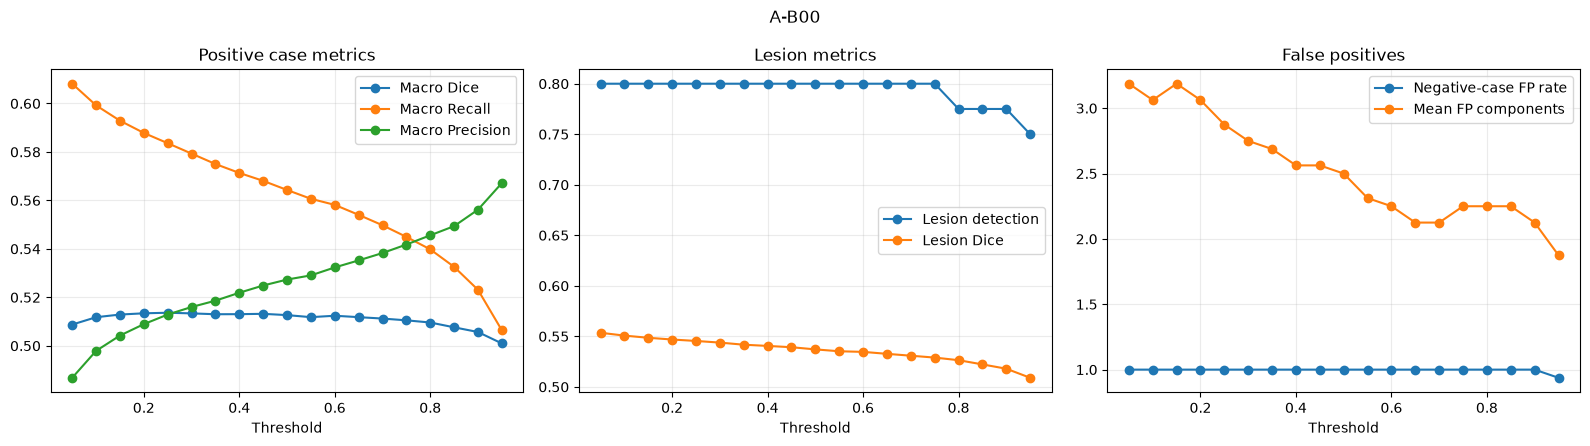

In [32]:
import matplotlib.pyplot as plt

if not ALL_METRICS.is_file():
    print("아직 통합 결과가 없습니다.")
else:
    # 예: "A-B03", "H-N140". None이면 첫 번째 완료 모델을 표시합니다.
    PLOT_EXPERIMENT = None
    available = sorted(metrics["experiment"].unique())
    experiment = PLOT_EXPERIMENT or available[0]
    plot_data = metrics[metrics["experiment"] == experiment].sort_values("threshold")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(plot_data["threshold"], plot_data["positive_macro_dice"], marker="o", label="Macro Dice")
    axes[0].plot(plot_data["threshold"], plot_data["positive_macro_recall"], marker="o", label="Macro Recall")
    axes[0].plot(plot_data["threshold"], plot_data["positive_macro_precision"], marker="o", label="Macro Precision")
    axes[0].set_title("Positive case metrics")
    axes[0].legend()

    axes[1].plot(plot_data["threshold"], plot_data["lesion_detection_rate"], marker="o", label="Lesion detection")
    axes[1].plot(plot_data["threshold"], plot_data["mean_lesion_dice_including_missed"], marker="o", label="Lesion Dice")
    axes[1].set_title("Lesion metrics")
    axes[1].legend()

    axes[2].plot(plot_data["threshold"], plot_data["negative_case_any_fp_rate"], marker="o", label="Negative-case FP rate")
    axes[2].plot(plot_data["threshold"], plot_data["mean_fp_components_per_negative_case"], marker="o", label="Mean FP components")
    axes[2].set_title("False positives")
    axes[2].legend()

    for axis in axes:
        axis.set_xlabel("Threshold")
        axis.grid(alpha=0.25)
    fig.suptitle(experiment)
    fig.tight_layout()
    plt.show()

## 결과 파일

- `runs/threshold_sweeps/all_completed_models/per_model/<experiment>_fold<fold>.csv`
- `runs/threshold_sweeps/all_completed_models/all_models_threshold_metrics.csv`
- `runs/threshold_sweeps/all_completed_models/selected_thresholds.csv`
- `runs/threshold_sweeps/all_completed_models/threshold_sweep.log`

추천 threshold를 확정한 뒤 test 데이터에는 해당 값을 변경하지 않고 한 번만 적용합니다.